# Can we predict depression using words written on twitter?

In [1]:
# Importing Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import nltk # This package is so we can parse out "stop words". Words like "the", "and", etc.
from nltk.corpus import stopwords
import operator # useful functions 

In [2]:
tweets_df = pd.read_csv('sentiment_tweets3.csv')
tweets_df

,Index,message,label
0,106,just had a real good moment. i missssssssss hi...,0
1,217,is reading manga http://plurk.com/p/mzp1e,0
2,220,@comeagainjen http://twitpic.com/2y2lx - http:...,0
3,288,@lapcat Need to send 'em to my accountant tomo...,0
4,540,ADD ME ON MYSPACE!!! myspace.com/LookThunder,0
...,...,...,...
10309,802309,No Depression by G Herbo is my mood from now o...,1
10310,802310,What do you do when depression succumbs the br...,1
10311,802311,Ketamine Nasal Spray Shows Promise Against Dep...,1
10312,802312,dont mistake a bad day with depression! everyo...,1


In [3]:
# We need a training dataset and a testing dataset. Let´s do the 80 perc as training and 20 perc as test
Xraw_train, Xraw_test, Yraw_train, Yraw_test = train_test_split(tweets_df["message"], tweets_df["label"], test_size=0.2, random_state=42)

In [8]:
# This function will parse our tweets into "ngrams"
def generate_N_grams(text,ngram=1):
    #Separating the sentence in words except for the common words like and or with
    words=[word for word in text.split(" ") if word not in set(stopwords.words('english'))] #"the dog eats food and drinks water" 
    #print("Sentence after removing stopwords:",words) #['dog', 'eats', 'food', 'drinks', 'water'] if ngram=3
    temp=zip(*[words[i:] for i in range(0,ngram)])#[('dog', 'eats', 'food'), ('eats', 'food', 'drinks'), ('food', 'drinks', 'water')]
    ans=[' '.join(ngram) for ngram in temp] # ['dog eats food', 'eats food drinks', 'food drinks water']
    return ans
# Ngram function from: https://www.analyticsvidhya.com/blog/2021/09/what-are-n-grams-and-how-to-implement-them-in-python/

In [9]:
def from_tweets2features(X,Y,n):
    df = pd.concat([X, Y], axis=1, names=['message', 'label'])
    
    # Choosing the messages from the tweets with label 1 (the depression tweets)
    dep_tweets = df[df.label==1].message
    # Choosing the messages from the tweets with label 0 (the neutral tweers)
    neut_tweets = df[df.label==0].message

    # Empty dictionary of ngrams from depression words
    ngrams_dep = {}
    ngrams_neut = {}
    
    for t in dep_tweets:
    
        # For each word in the depressive tweets generate 1-grams 
        ind_ngrams = generate_N_grams(t,n) #now we have each word but each one is not a string anymore, is a list
    
        # For each 1-gram in the 1-grams
        # For each element in the list
        for i in ind_ngrams:
            if i in ngrams_dep.keys(): # if you already have the word in the dictionary
                ngrams_dep[i]+=1 # then add 1 to the counter
            else: # if you do not have the word in the dictionary
                ngrams_dep[i]=1 #asign a 1 to each word (this happens first)
                    
    
    # The same as before but with neutral words
    for t in neut_tweets:
        
        ind_ngrams = generate_N_grams(t,1)
        
        for i in ind_ngrams:
            if i in ngrams_neut.keys():
                ngrams_neut[i]+=1
            else:
                ngrams_neut[i]=1

    # We want the most common words, the words that appear the most.
    # For this we have the words with its respective number of time that it appears
    # we order by number of time it appears
    sorted_ngrams_dep = sorted(ngrams_dep.items(), key=operator.itemgetter(1)) # For depression tweets
    sorted_ngrams_neut = sorted(ngrams_neut.items(), key=operator.itemgetter(1)) # For neutraltweets
    # we get the top 5 most common words
    top_five_dep = sorted_ngrams_dep[-5:] # For depression tweets
    top_five_neut = sorted_ngrams_neut[-5:] # For neutraltweets

    features_list = []

    # Now we want a dataframe 
    for index, row in df.iterrows():
        temporal_list = []
    
        # If the top 5 depression words are in each message append 1.
        for x in top_five_dep:
            if x[0] in row['message']:
                temporal_list.append(1)
            else:
                temporal_list.append(0)
        # If the top 5 neutral words are in each message append 1.
        for x in top_five_neut:
            if x[0] in row['message']:
                temporal_list.append(1)
            else:
                temporal_list.append(0)
                
        temporal_list.append(row['label'])
        features_list.append(temporal_list)
    
    # The first 5 are for the first 5 appearances of depression, and then the 5 appearances of neutral and the appearance of the label
    df_features = pd.DataFrame(features_list, columns = ['dfeat1','dfeat2','dfeat3','dfeat4','dfeat5','nfeat1','nfeat2','nfeat3','nfeat4','nfeat5','label'] )
    return df_features



In [56]:

def Depression_predictor(df_train, df_test):
    # First, lets state which variables we will use to predict, and which one will be the target one
    
    # X = predictor features
    X_train = df_train .drop("label", axis=1) # we preserve all the columns (axis=1) except label
    # Y = target variable
    Y_train = df_train ["label"]
    
    # X = predictor features
    X_test = df_test .drop("label", axis=1) # we preserve all the columns (axis=1) except label
    # Y = target variable
    Y_test = df_test["label"]
    
    
    #Create the model
    model= DecisionTreeClassifier(random_state=42)
    
    # Training the model
    model.fit(X_train, Y_train)
    
    #Predict
    Y_pred = model.predict(X_test)
    
    # Evaluate
    print("Accuracy:", accuracy_score(Y_test,Y_pred))
    print("\nConfusion matrix:\n", confusion_matrix(Y_test, Y_pred))
    print("\nClassification report:\n", classification_report(Y_test, Y_pred))

    cm = confusion_matrix(Y_test, Y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    
    plt.figure(figsize=(16,10))
    plot_tree(
        model,
        feature_names=X_train.columns,
        class_names=['dep', 'neut'],
        filled=True
    )
    plt.show()

In [57]:
# Assigning 3 different N-grams for the demonstration
df_train = {}
df_test= {}

for i in range(3):
    df_train[i+1]  = from_tweets2features(Xraw_train,Yraw_train, i+1)
    df_test[i+1]  = from_tweets2features(Xraw_test,Yraw_test, i+1)

## For 1-gram

Accuracy: 0.9689772176442074

Confusion matrix:
 [[1614    0]
 [  64  385]]

Classification report:
               precision    recall  f1-score   support

           0       0.96      1.00      0.98      1614
           1       1.00      0.86      0.92       449

    accuracy                           0.97      2063
   macro avg       0.98      0.93      0.95      2063
weighted avg       0.97      0.97      0.97      2063



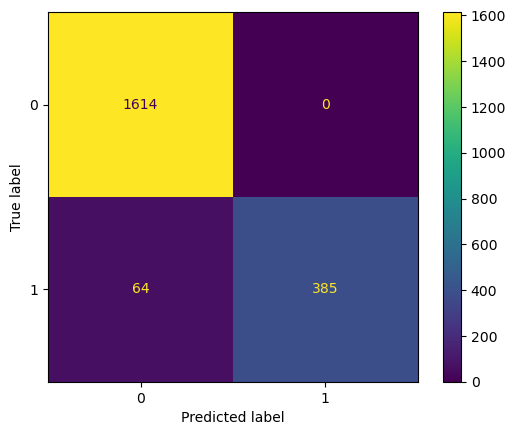

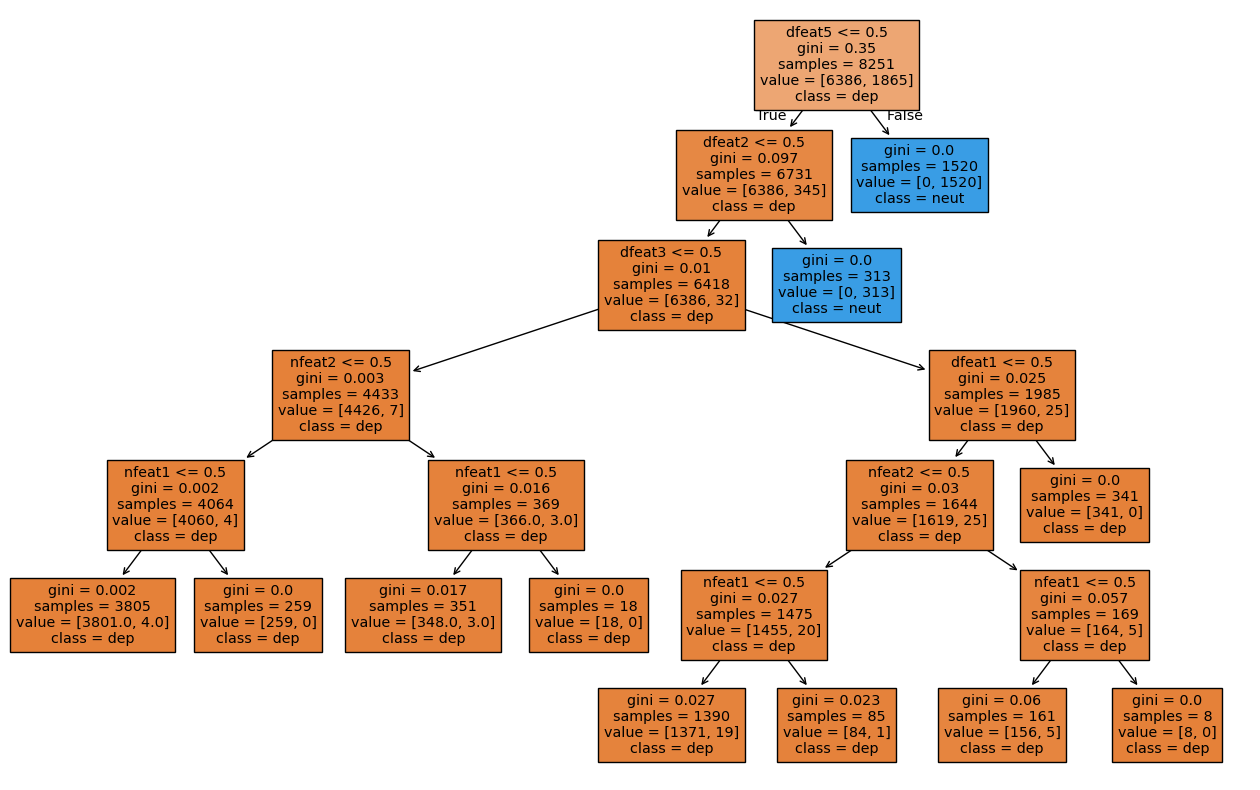

In [58]:
#df_train1  = from_tweets2features(Xraw_train,Yraw_train,1)
#df_test1  = from_tweets2features(Xraw_test,Yraw_test,1)

Depression_predictor(df_train[1], df_test[1])

Results interpretation:

[[TN FP 


  FN TP]]

- 1614 true negatives: were class 0 and the model predicted 0
- 64 false negatives: were class 0 and the model predicted 1
- 0 false positives: were class 1 and the model predicted 0
- 385 true positives: were class 1 and the model predicted 1

The decision tree achieved very high predictive performance, with an accuracy of 96.89% on the test set. The confusion matrix shows that all class 0 cases were correctly identified, while only 64 class 0 cases were misclassified as class 1.

## For pairs (2-grams)

Accuracy: 0.36694134755210855

Confusion matrix:
 [[ 481 1133]
 [ 173  276]]

Classification report:
               precision    recall  f1-score   support

           0       0.74      0.30      0.42      1614
           1       0.20      0.61      0.30       449

    accuracy                           0.37      2063
   macro avg       0.47      0.46      0.36      2063
weighted avg       0.62      0.37      0.40      2063



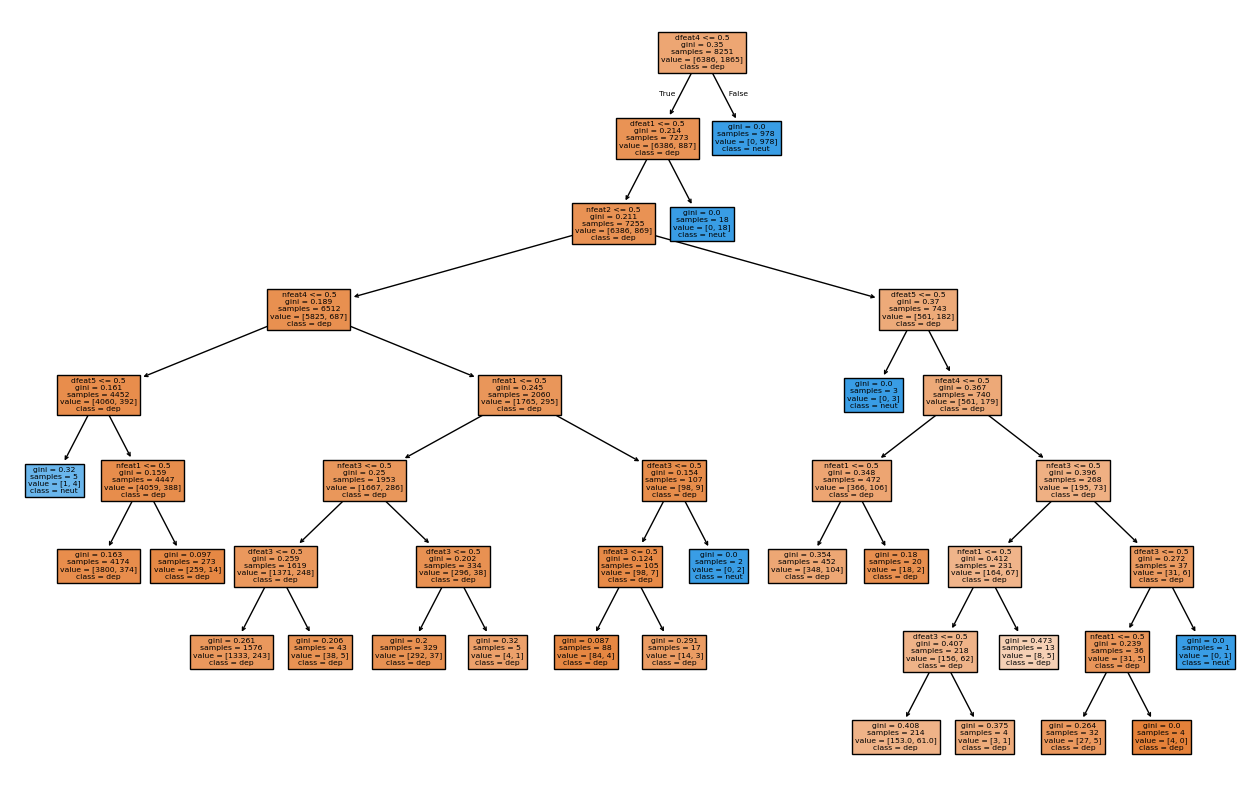

In [54]:
#df_train2  = from_tweets2features(Xraw_train,Yraw_train,2)
#df_test2  = from_tweets2features(Xraw_test,Yraw_test,2)

Depression_predictor(df_train[2], df_test[2])

## For Triplets (3-grams)

Accuracy: 0.7809015996122152

Confusion matrix:
 [[1607    7]
 [ 445    4]]

Classification report:
               precision    recall  f1-score   support

           0       0.78      1.00      0.88      1614
           1       0.36      0.01      0.02       449

    accuracy                           0.78      2063
   macro avg       0.57      0.50      0.45      2063
weighted avg       0.69      0.78      0.69      2063



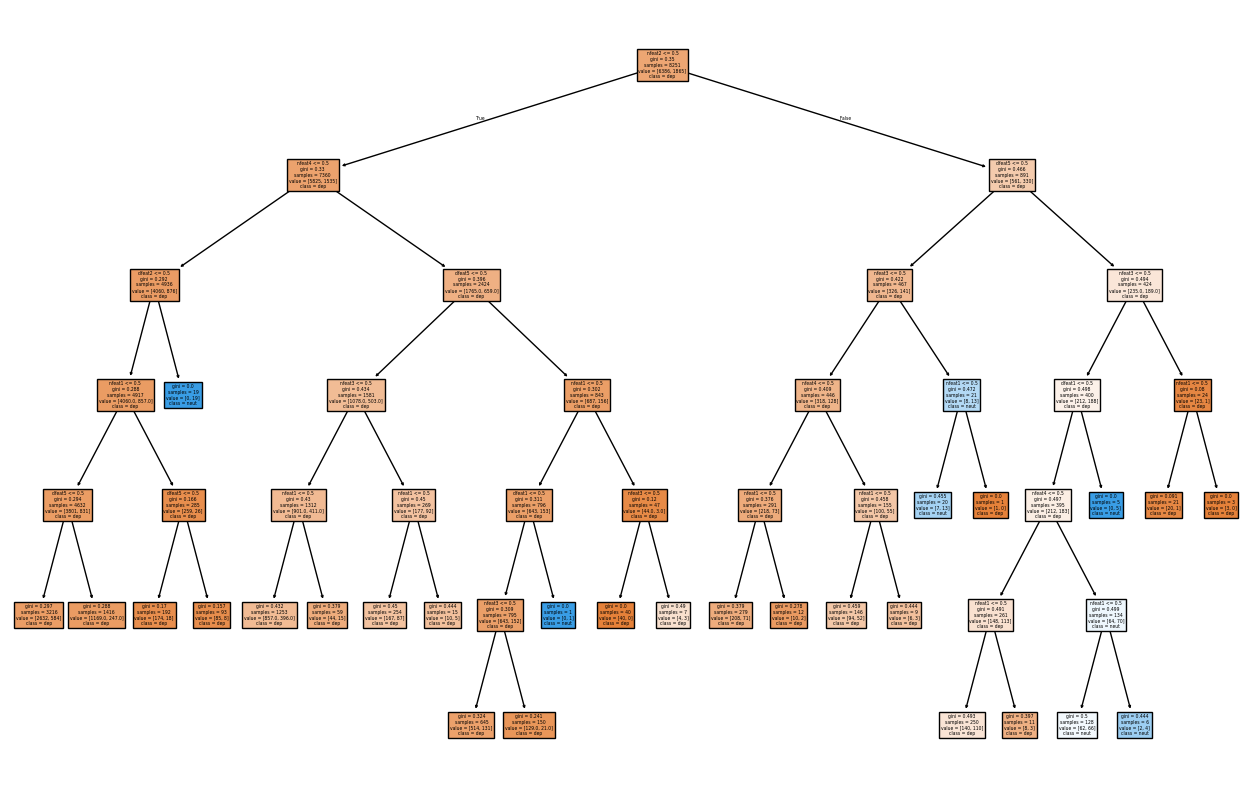

In [55]:
Depression_predictor(df_train[3], df_test[3])